# Partial Derivatives: Slopes in Higher Dimensions
So far, we've looked at functions with a single input, like $f(x)$. But what if a funciton depends on multiple variables, like $f(x, y)$? This is common in real applications, for example, the temperature in a room might depend on your $(x, y)$ position.

A partial derivative is the answer. It's the derivative of a function of serveral variables with respect to one of those variables, while treating all the other variables as constants.

Imagine a 3D landscape defined by $z = f(x, y)$. If you are standing at a point $(x, y)$, the partial derivative with respect to $x$ (written as $\frac{\partial f} {\partial y}$) is the slope in the y-direction (e.g., North-South)

The definition is very similar to the one we've already used. To find the partial derivatives with respect to $x$, we use the limit definition, but only $x$ changes:
$$
\frac{\partial f}{\partial x}(x, y) = \lim_{h \to 0} \frac{f(x+h,y) - f(x,y)}{h}
$$

and for $y$:
$$
\frac{\partial f}{\partial y}(x, y) = \lim_{h \to 0} \frac{f(x,y+h) - f(x,y)}{h}
$$

Let's calculate this numerically. We can reuse our `numerical_derivative` function, but we need to be clever about how we pass the function to it. Python's `lambda` is useful here to create temporary, single-variable functions where the other variables are "frozen" at a specific value.

In [37]:
# A function of two variables
def f_xy(x, y):
    return x**2 * y + 2*x + y**3

# We can resue our numerical derivative function
def numerical_derivative(f, x, h=1e-7):
    return (f(x + h) - f(x)) / h

# Point where we want to find the pertial derivatives
x_val, y_val = 3, 4

# --- Partial derivative with respect to x
# Treat y as a constant (y_val = 4)
# We create a temporary function of x only
f_wrt_x = lambda x: f_xy(x, y_val)

# Now we can calculate the derivative of this new function at x_val
partial_x = numerical_derivative(f_wrt_x, x_val)
print(f"The partial derivative ∂f/∂x at (x, y) = ({x_val}, {y_val}) is approximately: {partial_x:.8f}")

# The symbolic derivative ∂f/∂x is 2xy + 2.
# At (3, 4), this is 2 * 3 * 4 + 2 = 26. Our approximation should be close
print(f"The exact partial derivative ∂f/∂x is 2xy +2 = {2*x_val*y_val+2}")

# --- Partial derivative with respect to y ---
# Treat x as a constant (x_val = 3)
# We create a temporary function of y only
f_wrt_y = lambda y: f_xy(x_val, y)

# Calculate the derivative of this function at y_val
partial_y = numerical_derivative(f_wrt_y, y_val)
print(f"The partial derivative ∂f/∂x at (x, y) = ({x_val}, {y_val}) is approximately: {partial_y:.8f}")

# The symbolic derivative ∂f/∂y is x² + 3y².
# At (3, 4), this is 3² + 3*4² = 9 + 48 = 57.
print(f"The exact partial derivative ∂f/∂y is x² + 3y² = {x_val**2 + 3*y_val**2}")
      

The partial derivative ∂f/∂x at (x, y) = (3, 4) is approximately: 26.00000045
The exact partial derivative ∂f/∂x is 2xy +2 = 26
The partial derivative ∂f/∂x at (x, y) = (3, 4) is approximately: 57.00000131
The exact partial derivative ∂f/∂y is x² + 3y² = 57


## The Gradient: The Direction of Steepest Ascent
We've calculated the slope in the x-direction ($\frac{\partial f}{\partial x}$) and the slope in the y-direction ($\frac{\partial f}{\partial y}$). What if we combine these tow values into a vector?

That vector is called the gradient, and it's denoted by $\nabla f$ (pronounced "nabla f").
$$
\nabla f (x,y) = +\left[ \frac{\partial f}{\partial x} \frac{\partial f}{\partial y} \right]
$$
The gradient is incredibly important for two reasons:
1. **Direction:** The gradient vector at a point $(x, y)$ always points in the direction of the steepest ascent of the function. If you were on a mountain and wanted to climb up as quickly as possible, you would walk in the direction of the gradient.
2. **Magnitude:** The length (magnitude) of the gradient vector tells you how steep that ascent is. A longer vector means a steeper slope.

Conversely, the negative gradient ($-\nabla f$) points in the direction of the steepest descent. This also is the core idea behind gradient descent.



### 3D Visualization: The Functions Landscape
First, let's visualize the function $f(x, y)$ itself as a 3D surface. This shows the actual shape of the landscape of the function.

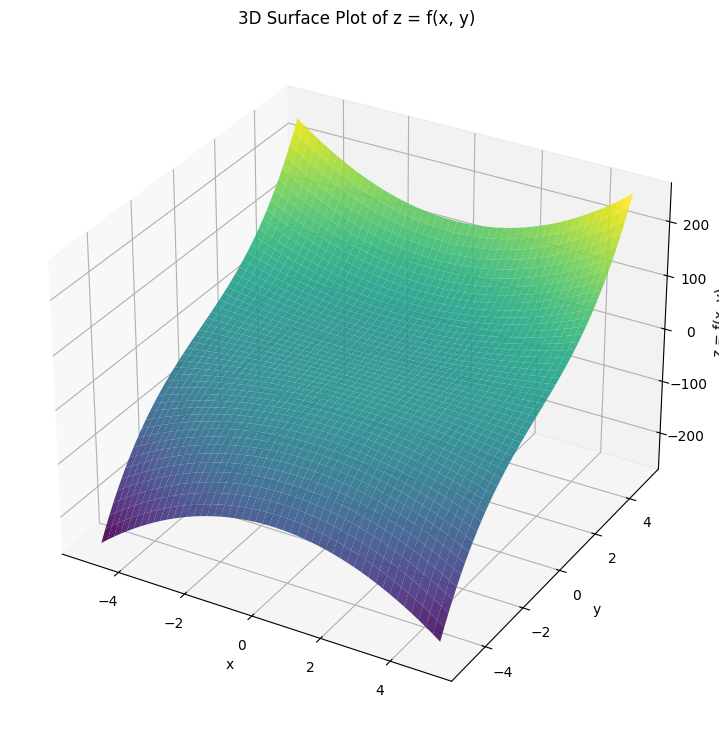

In [43]:
import numpy as np
import matplotlib.pyplot as plt

def f_xy(x, y):
    return x**2 * y + 2*x + y**3

x_vals = np.linspace(-5, 5, 50) # Using more points for a smoother surface
y_vals = np.linspace(-5, 5, 50)
X, Y = np.meshgrid(x_vals, y_vals)
Z = f_xy(X, Y)

# Create the 3D plot
fig = plt.figure(figsize=(10, 9))
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.9)

ax.set_title('3D Surface Plot of z = f(x, y)')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z = f(x, y)')
ax.view_init(elev=30, azim=-60) # Adjust viewing angle for better perspective
plt.show()

## 2D: Representation: Gradient Field Heatmap
Let's visualize this. We'll create a 2D heatmap, where color represents the value of $f(x, y)$, then overlay arrows (a "quiver plot") representing the gradient vectors at various points. Arrows should be point uphill from darker regions to brighter regions. The yellow areas correspond to high peaks, the purple areas correspond to deep valleys.

Let's look at one arrow on this heatmap, representing a single gradient vector:

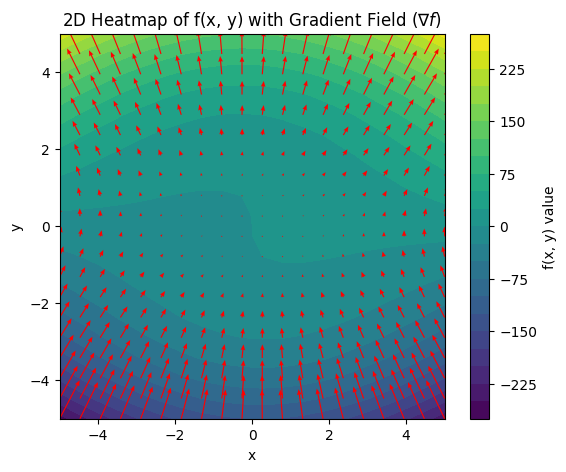

For function f(x, y): x**2 * y + 2*x +y**3
At point (-1, -2):
  - The function value f(x,y) is: -12
  - The gradient ∇f is: [ 6 13] (dx=6, dy=13)
At point (-3, 4):
  - The function value f(x,y) is: 94
  - The gradient ∇f is: [-22  57] (dx=-22, dy=57)
At point (3, 1):
  - The function value f(x,y) is: 16
  - The gradient ∇f is: [ 8 12] (dx=8, dy=12)


In [39]:
import numpy as np
import matplotlib.pyplot as plt

# Our function from before
def f_xy(x, y):
    return x**2 * y + 2*x + y**3

# The symbolic gradient of f(x,y)
# ∂f/∂x = 2xy + 2
# ∂f/∂y = x² + 3y²
def gradient_f_xy(x, y):
    df_dx = 2*x*y + 2
    df_dy = x**2 + 3*y**2
    return np.array([df_dx, df_dy])

# --- Create the visualization ---

# Set up a grid of points
x_vals = np.linspace(-5, 5, 20)
y_vals = np.linspace(-5, 5, 20)
X, Y = np.meshgrid(x_vals, y_vals)

# Calculate the function's value Z at each point in the grid
Z = f_xy(X, Y)

# Calculate the gradient at each point in the grid
# We need to store the x and y components of the gradient seperately
U, V = gradient_f_xy(X, Y)

# Craete the plot
plt.figure(figsize=(6.25, 5))

# Create a filled contour plot (the heatmap)
# The 'levels' argument helps create more distinc color bands
contour = plt.contourf(X, Y, Z, levels=20, cmap='viridis')

# Add a color bar to show the mapping of Z values to colors
plt.colorbar(contour, label='f(x, y) value')

# Overlay the gradient vectors (the quiver plot)
# The arrows show the direction and magnitude of the gradient
plt.quiver(X, Y, U, V, color='red', scale=1000, headwidth=4)

plt.title(r'2D Heatmap of f(x, y) with Gradient Field ($\nabla f$)')
plt.xlabel('x')
plt.ylabel('y')
plt.axis('scaled')
plt.show()

# --- Point of Interests ---
px1, py1 = -1, -2
px2, py2 = -3, 4
px3, py3 = 3, 1
points = [(px1, py1), (px2, py2), (px3, py3)]

# Take a few samples
f_val1 = f_xy(px1, py1)
f_val2 = f_xy(px2, py2)
f_val3 = f_xy(px3, py3)
samples = [f_val1, f_val2, f_val3]

# Calculate gradients
grad_vector1 = gradient_f_xy(px1, py1)
grad_vector2 = gradient_f_xy(px2, py2)
grad_vector3 = gradient_f_xy(px3, py3)
gradients = [grad_vector1, grad_vector2, grad_vector3]

print(f"For function f(x, y): x**2 * y + 2*x +y**3")
i = 0;
for px, py in points:
    grad_vector = gradients[i]
    print(f"At point ({px}, {py}):")
    print(f"  - The function value f(x,y) is: {samples[i]}")
    print(f"  - The gradient ∇f is: {grad_vector} (dx={grad_vector[0]}, dy={grad_vector[1]})")
    i = i+1